# Thread Count 03: forecast to December 2027

What we forecast: US apparel imports (HS 61 and 62) from the world and from Bangladesh, monthly, October 2026 to December 2027.

How:

1. Test three simple methods on past data (four forecast start points, 12 months ahead each) and keep the one with the lowest error.
2. Forecast total US apparel imports with it, with an 80% range.
3. Turn that into Bangladesh value under three share scenarios, because Bangladesh's share is where the tariff story plays out.

Everything assumes today's tariffs (10% for Bangladesh on top of normal duty) stay in place. A new tariff change would break these numbers, which is why the scenarios matter more than the single line.

In [1]:
import duckdb, pandas as pd, numpy as np, matplotlib.pyplot as plt, warnings
from pathlib import Path
from statsmodels.tsa.holtwinters import ExponentialSmoothing
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "03_analysis" else Path.cwd()
con = duckdb.connect(str(ROOT / "01_data/processed/thread_count.duckdb"), read_only=True)
GREEN, OCHRE, TOMATO, SLATE = "#1D4A35", "#B87318", "#F2462E", "#7D8D99"
plt.rcParams.update({"figure.facecolor": "#F7F1E6", "axes.facecolor": "#F7F1E6", "axes.edgecolor": "#DCCFB6",
                     "axes.grid": True, "grid.color": "#E6DCC8", "axes.spines.top": False, "axes.axisbelow": True,
                     "axes.spines.right": False, "font.size": 10, "text.color": "#16382A",
                     "axes.labelcolor": "#4F5E52", "xtick.color": "#4F5E52", "ytick.color": "#4F5E52"})
pd.set_option("display.float_format", "{:,.2f}".format)

def series(sql):
    s = con.sql(sql).df().set_index("month")["v"]; s.index = pd.to_datetime(s.index); return s.asfreq("MS")
world = series("select month, sum(gen_value) v from silver.world where chapter in ('61','62') group by 1 order by 1")
bd = series("select month, sum(gen_value) v from silver.imports where chapter in ('61','62') and country='bangladesh' group by 1 order by 1")
share = bd / world
print(world.index.min().date(), "to", world.index.max().date(), len(world), "months")

2017-01-01 to 2026-09-01 117 months


## 1. Backtest

In [2]:
def ets_fit(s):
    return ExponentialSmoothing(np.log(s), trend="add", damped_trend=True, seasonal="add", seasonal_periods=12).fit()
def f_ets(s, h): return np.exp(ets_fit(s).forecast(h)).values
def f_snaive(s, h): return np.array([s.iloc[-12 + (i % 12)] for i in range(h)])
def f_snaive_growth(s, h): return f_snaive(s, h) * s.iloc[-12:].sum() / s.iloc[-24:-12].sum()

def mape(p, a): return float(np.mean(np.abs(p - a) / a) * 100)
origins = ["2023-09-01", "2024-09-01", "2025-03-01", "2025-09-01"]
rows = []
for o in origins:
    o = pd.Timestamp(o)
    for name, s in [("world", world), ("bangladesh", bd)]:
        tr, te = s[:o], s[o + pd.offsets.MonthBegin(1):][:12]
        for fname, f in [("ets", f_ets), ("same month last year", f_snaive), ("last year x growth", f_snaive_growth)]:
            rows.append({"series": name, "start": o.date(), "method": fname, "mape": mape(f(tr, len(te)), te.values)})
        # Bangladesh as recent share x world forecast
        if name == "bangladesh":
            sh = (bd[:o] / world[:o]).iloc[-6:].mean()
            rows.append({"series": name, "start": o.date(), "method": "6 month share x world ets",
                         "mape": mape(sh * f_ets(world[:o], len(te)), te.values)})
bt = pd.DataFrame(rows)
bt.pivot_table(index=["series", "method"], columns="start", values="mape").assign(
    average=lambda d: d.mean(axis=1)).round(1)

start                                 2023-09-01  2024-09-01  2025-03-01  \
series     method                                                          
bangladesh 6 month share x world ets       10.90       13.00       14.50   
           ets                             10.10        9.50       11.30   
           last year x growth              18.50       26.40       18.70   
           same month last year            19.20       18.00       12.80   
world      ets                              5.60        5.40       12.30   
           last year x growth              13.70       11.40       15.70   
           same month last year             9.90        9.50       10.30   

start                                 2025-09-01  average  
series     method                                          
bangladesh 6 month share x world ets        9.50    12.00  
           ets                             11.10    10.50  
           last year x growth              27.70    22.80  
           same month last year            10.30    15.10  
world      ets                              5.20     7.10  
           last year x growth              14.00    13.70  
           same month last year             9.80     9.90

Error is mean absolute percentage error on monthly values. The start in March 2025 includes the tariff shock, so every method does worse there.

The damped trend ETS model (exponential smoothing on the log of value, with a monthly seasonal pattern) wins for the world total. For Bangladesh, forecasting it directly with ETS is a little more accurate (about 10.5% against 12.0%) than taking its recent share times the world forecast. We still use share times world for the scenarios, because it lets us set the share explicitly, and we keep the direct ETS forecast as a cross-check.

## 2. Total US apparel imports

Monthly range: plus or minus 11.3%


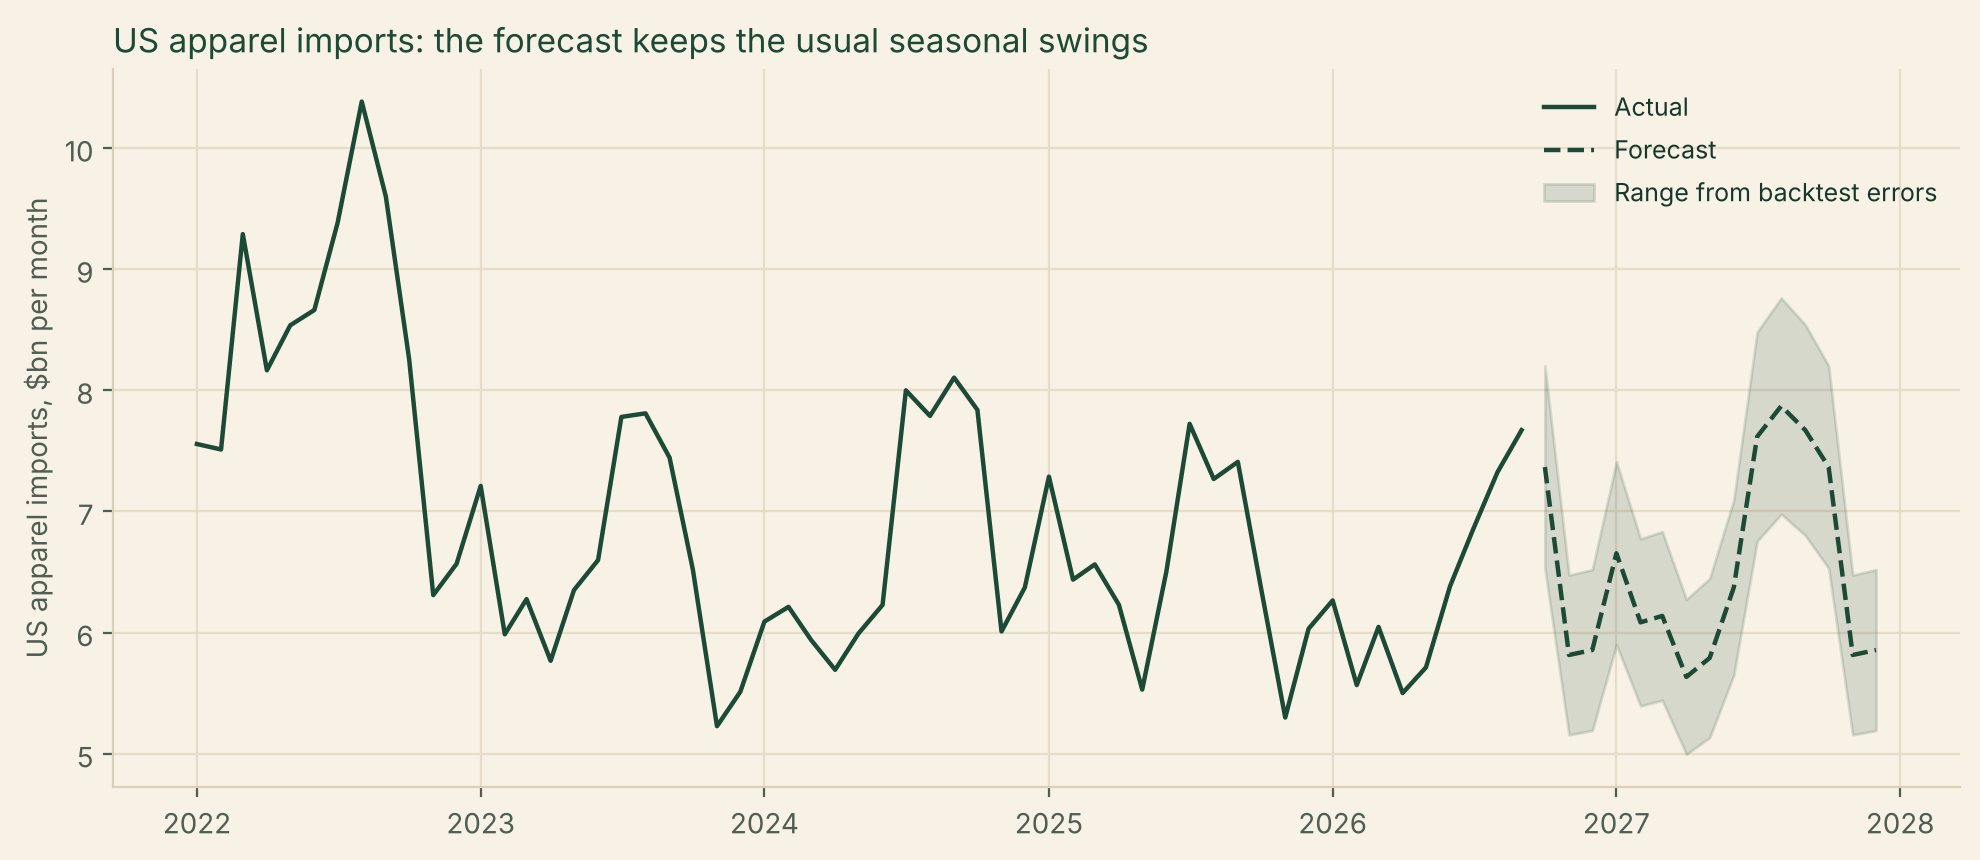

In [3]:
H = 15  # Oct 2026 to Dec 2027
fit = ets_fit(world)
idx = pd.date_range(world.index[-1] + pd.offsets.MonthBegin(1), periods=H, freq="MS")
point = np.exp(fit.forecast(H)); point.index = idx
# Range from the backtest: 80th percentile of absolute monthly errors of the ETS model across the four start points
errs = []
for o in origins:
    o = pd.Timestamp(o); te = world[o + pd.offsets.MonthBegin(1):][:12]
    errs += list(np.abs(f_ets(world[:o], len(te)) / te.values - 1))
q = float(np.quantile(errs, .80))
lo, hi = point * (1 - q), point * (1 + q)
print(f"Monthly range: plus or minus {q:.1%}")

fig, ax = plt.subplots(figsize=(10, 4.4))
ax.plot(world["2022":].index, world["2022":] / 1e9, color=GREEN, lw=1.6, label="Actual")
ax.plot(idx, point / 1e9, color=GREEN, lw=1.6, ls="--", label="Forecast")
ax.fill_between(idx, lo / 1e9, hi / 1e9, color=GREEN, alpha=.15, label="Range from backtest errors")
ax.set_ylabel("US apparel imports, $bn per month")
ax.set_title("US apparel imports: the forecast keeps the usual seasonal swings", loc="left", fontsize=12, color=GREEN)
ax.legend(frameon=False, fontsize=9); plt.tight_layout(); plt.show()

In [4]:
def year_total(actual, fc, y):
    a = actual[str(y)].sum() if str(y) in actual.index.year.astype(str) else 0
    f = fc[str(y)].sum() if (fc.index.year == y).any() else 0
    return a + f
wy = pd.DataFrame({
    "year": [2024, 2025, 2026, 2027],
    "world_bn": [world["2024"].sum()/1e9, world["2025"].sum()/1e9,
                 (world["2026"].sum() + point["2026"].sum())/1e9, point["2027"].sum()/1e9],
}).set_index("year")
# Yearly range: worst 12-month total error of the ETS model in the backtest
tot_err = []
for o in origins:
    o = pd.Timestamp(o); te = world[o + pd.offsets.MonthBegin(1):][:12]
    tot_err.append(abs(f_ets(world[:o], len(te)).sum() / te.values.sum() - 1))
qa = max(tot_err)
print("12-month total errors in backtest:", [f"{e:.1%}" for e in tot_err])
wy.loc[2027, "low_bn"] = wy.loc[2027, "world_bn"] * (1 - qa)
wy.loc[2027, "high_bn"] = wy.loc[2027, "world_bn"] * (1 + qa)
wy["change_pct"] = 100 * wy["world_bn"].pct_change()
wy

12-month total errors in backtest: ['0.6%', '2.8%', '11.6%', '2.0%']


,world_bn,low_bn,high_bn,change_pct
year,,,,
2024,80.27,NaN,NaN,NaN
2025,78.64,NaN,NaN,-2.03
2026,76.36,NaN,NaN,-2.89
2027,78.87,69.72,88.01,3.28


The 2027 low and high use the worst 12-month total error the model made in the backtest, so they are a cautious band, not a statistical interval.

## 3. Bangladesh under three share scenarios

In [5]:
recent = share.iloc[-6:].mean()
s24 = (bd["2024-01":"2024-09"].sum() / world["2024-01":"2024-09"].sum())
s26 = (bd["2026-01":"2026-09"].sum() / world["2026-01":"2026-09"].sum())
per_year = (s26 - s24) / 2
print(f"Share Jan to Sep 2024 {s24:.2%}, Jan to Sep 2026 {s26:.2%}, last 6 months {recent:.2%}")

months_out = np.arange(1, H + 1)
scen = {
    "share holds": pd.Series(recent, index=idx),
    "gain continues": pd.Series(recent + per_year * months_out / 12, index=idx),
    "back to 2024 share": pd.Series(np.linspace(recent, s24, H), index=idx),
}
# Seasonal share pattern: Bangladesh's share is not flat across the year, so carry its average monthly deviation
dev = (share["2017":"2025"].groupby(share["2017":"2025"].index.month).mean() / share["2017":"2025"].mean())
out = {}
for k, sh in scen.items():
    out[k] = sh * dev.reindex(idx.month).values * point
res = pd.DataFrame({k: [ (bd["2026"].sum() + v["2026"].sum())/1e9, v["2027"].sum()/1e9 ] for k, v in out.items()},
                   index=[2026, 2027])
direct = np.exp(ets_fit(bd).forecast(H)); direct.index = idx
res["direct ets (check)"] = [(bd["2026"].sum() + direct["2026"].sum())/1e9, direct["2027"].sum()/1e9]
res.loc[2025] = bd["2025"].sum()/1e9
res.loc[2024] = bd["2024"].sum()/1e9
res = res.sort_index()
res

Share Jan to Sep 2024 8.67%, Jan to Sep 2026 10.30%, last 6 months 10.08%


,share holds,gain continues,back to 2024 share,direct ets (check)
2024,7.05,7.05,7.05,7.05
2025,7.88,7.88,7.88,7.88
2026,7.80,7.82,7.78,7.75
2027,7.91,8.41,7.24,8.11


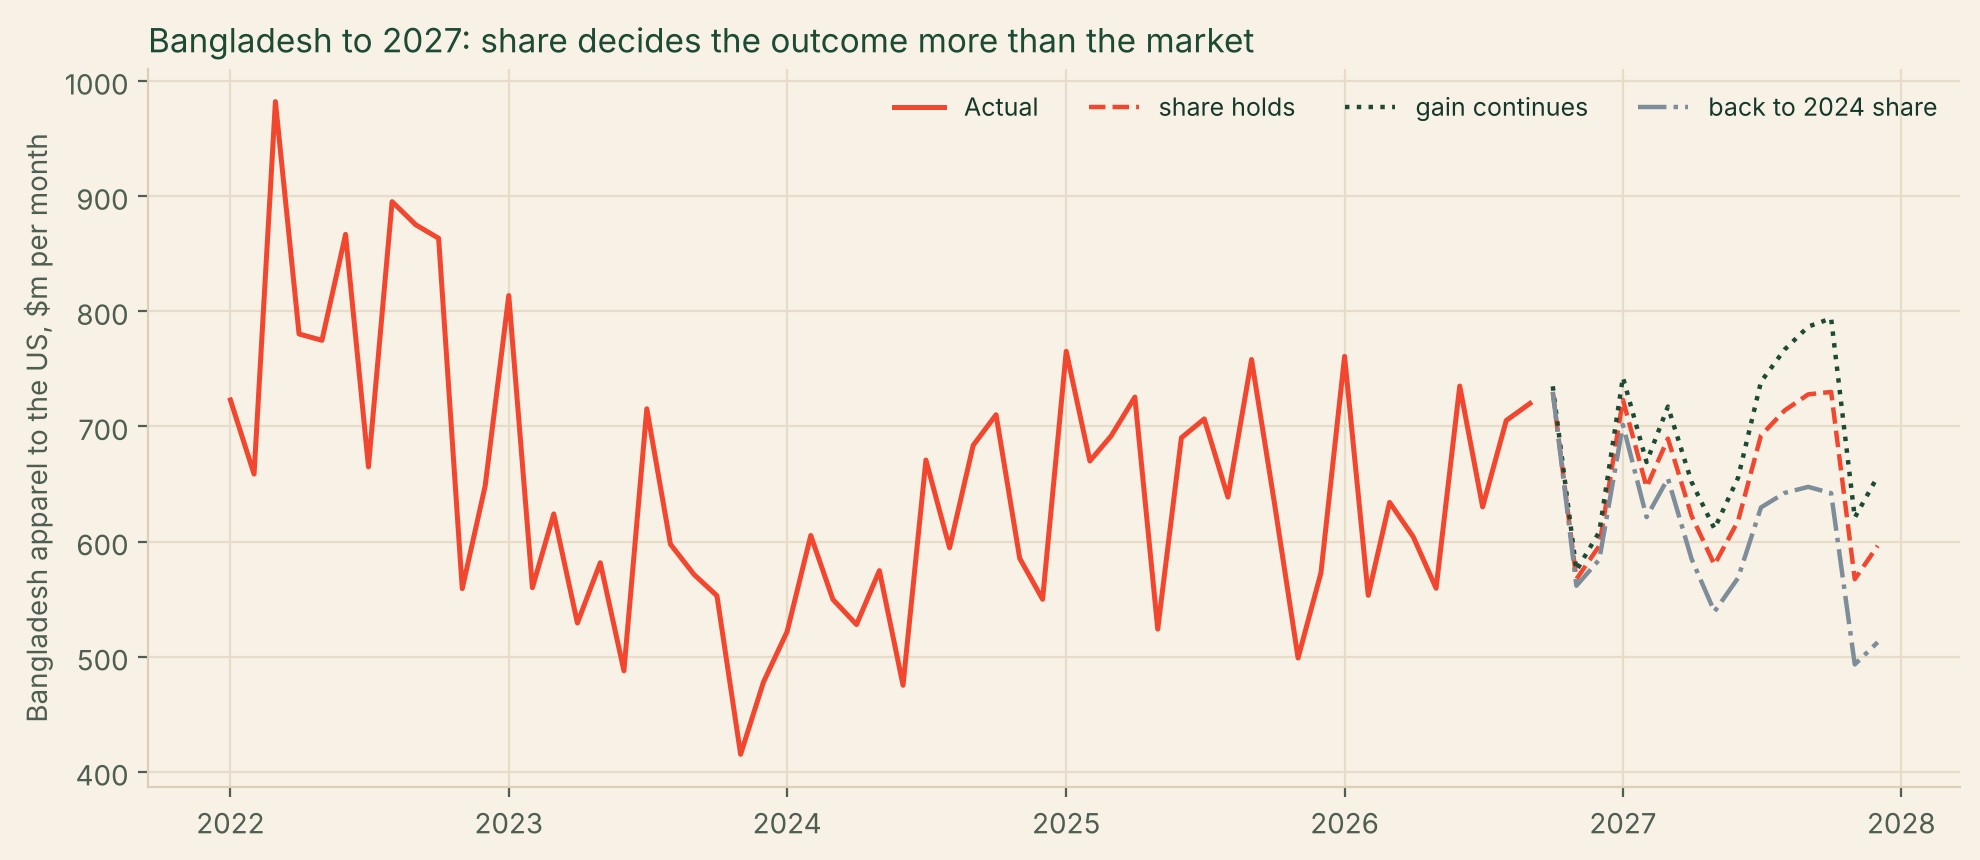

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.plot(bd["2022":].index, bd["2022":] / 1e6, color=TOMATO, lw=1.8, label="Actual")
for (k, v), ls, colr in zip(out.items(), ["--", ":", "-."], [TOMATO, GREEN, SLATE]):
    ax.plot(v.index, v / 1e6, ls=ls, color=colr, lw=1.6, label=k)
ax.set_ylabel("Bangladesh apparel to the US, $m per month")
ax.set_title("Bangladesh to 2027: share decides the outcome more than the market", loc="left", fontsize=12, color=GREEN)
ax.legend(frameon=False, fontsize=9, ncol=4); plt.tight_layout(); plt.show()

In [7]:
sc = res.loc[2027, list(scen)]
print(f"2027 range across scenarios: ${sc.min():.2f}bn to ${sc.max():.2f}bn, a spread of ${sc.max()-sc.min():.2f}bn.")
print(f"World cautious band for 2027 is ${wy.loc[2027,'low_bn']:.1f}bn to ${wy.loc[2027,'high_bn']:.1f}bn; "
      f"at the 'share holds' share that is ${recent*wy.loc[2027,'low_bn']:.2f}bn to ${recent*wy.loc[2027,'high_bn']:.2f}bn for Bangladesh.")

2027 range across scenarios: $7.24bn to $8.41bn, a spread of $1.17bn.
World cautious band for 2027 is $69.7bn to $88.0bn; at the 'share holds' share that is $7.03bn to $8.87bn for Bangladesh.


## Limits

* No tariff change is built in. The cotton route in the February 2026 deal, any change to the Section 301 rate, or IEEPA refunds would each shift these numbers.
* The share scenarios are assumptions, not estimates. "Gain continues" extends the 2024 to 2026 rate of gain; "back to 2024 share" assumes buyers move orders back to China or elsewhere.
* Next: `05_review/verify.py` recomputes the headline numbers a second way, straight from the raw files.